# Study 09 · 06 · E5 · What carries the skill: case history or climate?

The four-arm design of `evaluate_climate_without_history.py` (formulation S4_s2: Poisson count without the persistence offset or blend, NB2 exceedance, chronological Platt), refitted over all blocks with five seeds:

| Arm | Predictors |
|---|---|
| `geografia` | calendar (sine, cosine) + latitude, longitude, elevation |
| `clima_geografia` | + b3 climate block (lag 2) |
| `historia_geografia` | case history + calendar + geography (the predictors of `historia_geo`) |
| `clima_historia_geografia` | + b3 climate block |

Compared over 18 seasons, pooled. Probabilistic persistence and district climatology are the two reference forecasts.

In [1]:
import os
import sys
from pathlib import Path

os.environ.update({"DENGUEKAY_XGB_DEVICE": "cpu", "DENGUEKAY_XGB_NJOBS": "2", "OMP_NUM_THREADS": "2",
                   "OPENBLAS_NUM_THREADS": "1", "VECLIB_MAXIMUM_THREADS": "1", "MLFLOW_DISABLE_AGENT_HINT": "1"})
STUDY = Path.cwd().parent
sys.path.insert(0, str(STUDY / "code"))

import numpy as np
import pandas as pd

import common as c

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 60)
import matplotlib.pyplot as plt

import experiments as ex
import run_extra as rx

FIG = STUDY / "figures"
RES = c.OUTPUT / "resultados"
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)
base = pd.read_csv(c.OUTPUT / "baselines.csv.gz", dtype={"ubigeo": str}, parse_dates=["semana_inicio", "origen_cierre"])
names = ["geografia", "clima_geografia", "historia_geografia", "clima_historia_geografia"]
cols = ["semilla", "bloque", "horizonte", "ubigeo", "semana_inicio", "casos_Dengue", "brote", "probabilidad_calibrada"]
four = {n: ex.sse(c.read_arm(n, columns=cols, folder=rx.FOUR_ARMS_DIR)) for n in names}
s_pp, s_cl = ex.sse(base, "persistencia_prob"), ex.sse(base, "climatologia")

In [2]:
pairs = {"adding climate, no case history": ("clima_geografia", "geografia"),
         "adding climate, with case history": ("clima_historia_geografia", "historia_geografia"),
         "adding case history, no climate": ("historia_geografia", "geografia"),
         "adding case history, with climate": ("clima_historia_geografia", "clima_geografia")}
decomposition = pd.concat([ex.contrast(four[a], four[b]).assign(contrast=name) for name, (a, b) in pairs.items()])
decomposition = decomposition[["contrast", "horizonte", "brier_a", "brier_b", "cambio_agrupado_%", "ic95_agrupado", "cambio_igual_peso_%", "temporadas_a_mejor"]]
decomposition.to_csv(RES / "e5_descomposicion.csv", index=False)
decomposition.round(3)

,contrast,horizonte,brier_a,brier_b,cambio_agrupado_%,ic95_agrupado,cambio_igual_peso_%,temporadas_a_mejor
0,"adding climate, no case history",2,0.067,0.068,-1.888,"(-6.1, 3.3)",-1.557,10
1,"adding climate, no case history",3,0.067,0.068,-1.858,"(-5.86, 2.7)",-2.268,9
2,"adding climate, no case history",4,0.067,0.068,-1.854,"(-5.69, 2.57)",-2.382,9
0,"adding climate, with case history",2,0.029,0.029,-0.486,"(-1.64, 0.31)",-1.888,12
1,"adding climate, with case history",3,0.033,0.034,-0.780,"(-2.16, 0.16)",-2.606,12
2,"adding climate, with case history",4,0.037,0.038,-1.029,"(-2.62, 0.06)",-3.123,13
0,"adding case history, no climate",2,0.029,0.068,-57.698,"(-64.8, -48.96)",-56.903,18
1,"adding case history, no climate",3,0.034,0.068,-50.577,"(-58.36, -40.87)",-49.464,18
2,"adding case history, no climate",4,0.038,0.068,-44.641,"(-53.12, -34.25)",-43.505,18
0,"adding case history, with climate",2,0.029,0.067,-57.087,"(-64.14, -48.95)",-55.520,18


In [3]:
skill = []
for n in names:
    for ref_name, ref in (("vs climatology", s_cl), ("vs probabilistic persistence", s_pp)):
        t = ex.contrast(four[n], ref)
        skill.append(t.assign(arm=n, reference=ref_name, skill_pct=-t["cambio_agrupado_%"]))
skill = pd.concat(skill)[["arm", "reference", "horizonte", "skill_pct", "ic95_agrupado", "temporadas_a_mejor"]]
skill.to_csv(RES / "e5_habilidad.csv", index=False)
skill.pivot_table(index=["arm"], columns=["reference", "horizonte"], values="skill_pct").round(1)

reference                vs climatology             vs probabilistic persistence             
horizonte                             2     3     4                            2      3     4
arm                                                                                          
clima_geografia                     4.3   4.4   4.3                       -133.0 -100.5 -78.2
clima_historia_geografia           58.9  52.2  46.5                         -0.0   -0.2   0.4
geografia                           2.5   2.5   2.5                       -137.4 -104.4 -81.6
historia_geografia                 58.8  51.8  46.0                         -0.4   -1.0  -0.6

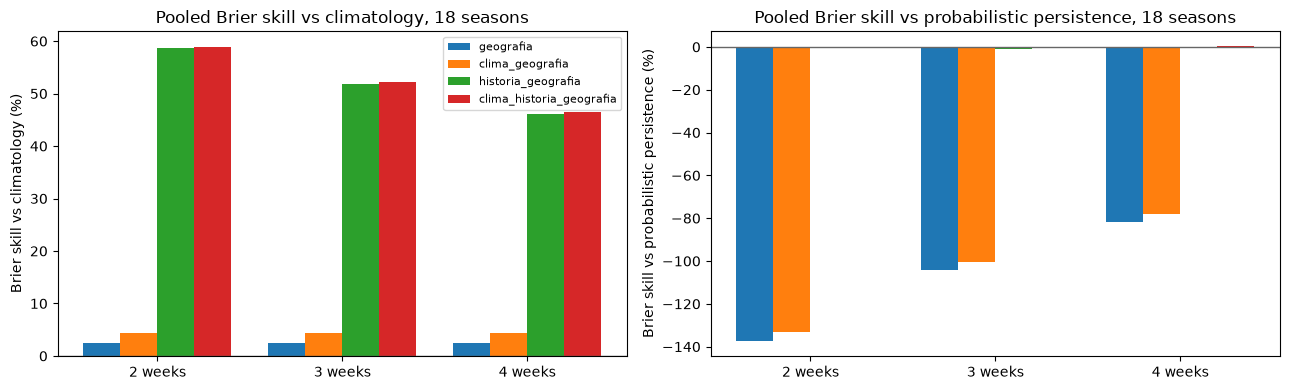

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, ref_name in zip(axes, ("vs climatology", "vs probabilistic persistence")):
    d = skill[skill.reference.eq(ref_name)]
    for k, n in enumerate(names):
        e = d[d.arm.eq(n)].sort_values("horizonte")
        ax.bar(np.arange(3) + (k - 1.5) * 0.2, e.skill_pct, width=0.2, label=n)
    ax.axhline(0, color="0.4", lw=1)
    ax.set_xticks(range(3), ["2 weeks", "3 weeks", "4 weeks"])
    ax.set_ylabel(f"Brier skill {ref_name} (%)")
    ax.set_title(f"Pooled Brier skill {ref_name}, 18 seasons")
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "e5_que_aporta_la_habilidad.png", dpi=160)